<a href="https://colab.research.google.com/github/aims-ai-research-foundations/Kenya-workshop-1/blob/main/course-labs/day5/day5-course7-practical-notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> <p><small>This notebook is made available subject to the licence and terms set out in <a href="https://creativecommons.org/licenses/by/4.0">https://creativecommons.org/licenses/by/4.0</a>.</small></p>

# Course 07 Lab: Accelerate Your Model

<p align="center">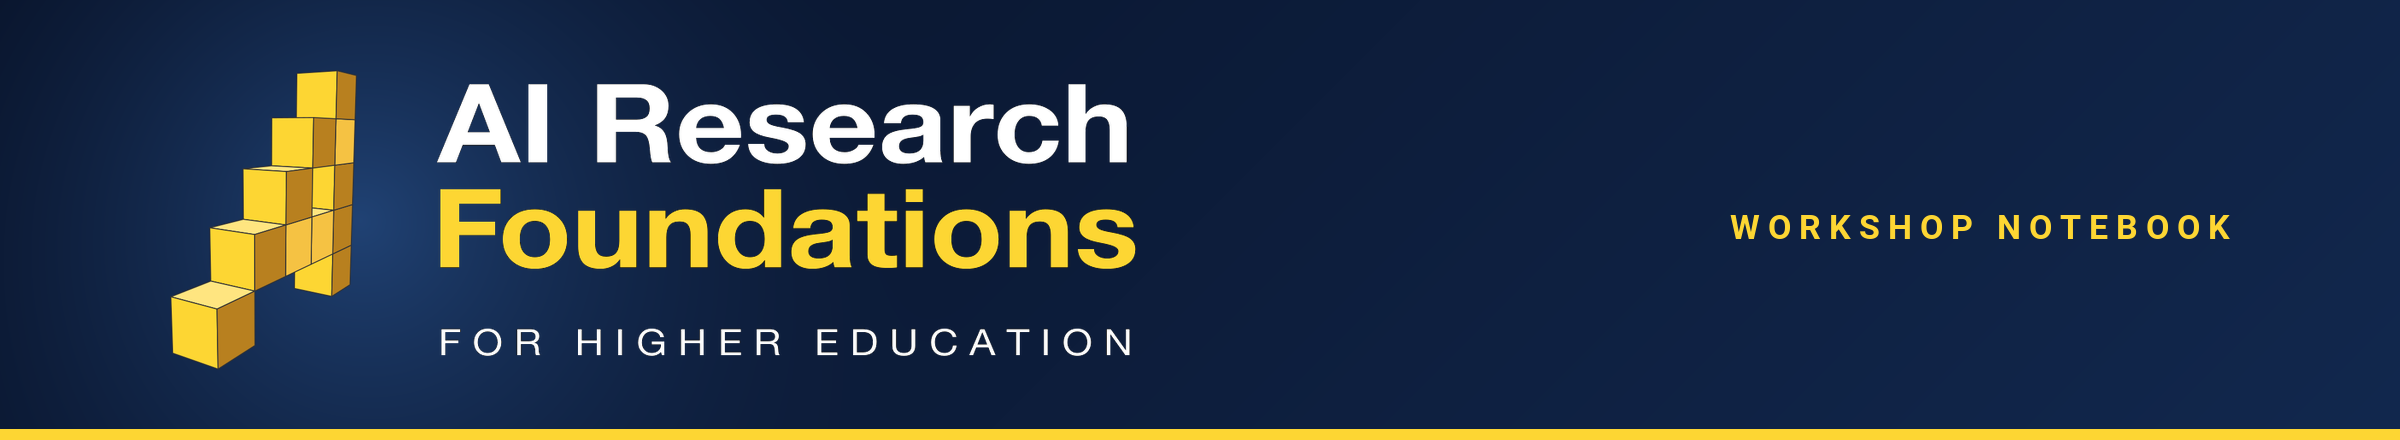</p>

**Time:** 60 minutes

### ⚠️ Before you do anything: save your own copy

This notebook opens in read-only playground mode. Go to **File → Save a copy in Drive** now, then work in that copy. If you skip this step, none of your answers will be saved and all your work will be lost when the tab closes.

## 🎯 The Challenge

**Our goal:** deploy a language model as a maths tutor for students in Kenya, like the one below.

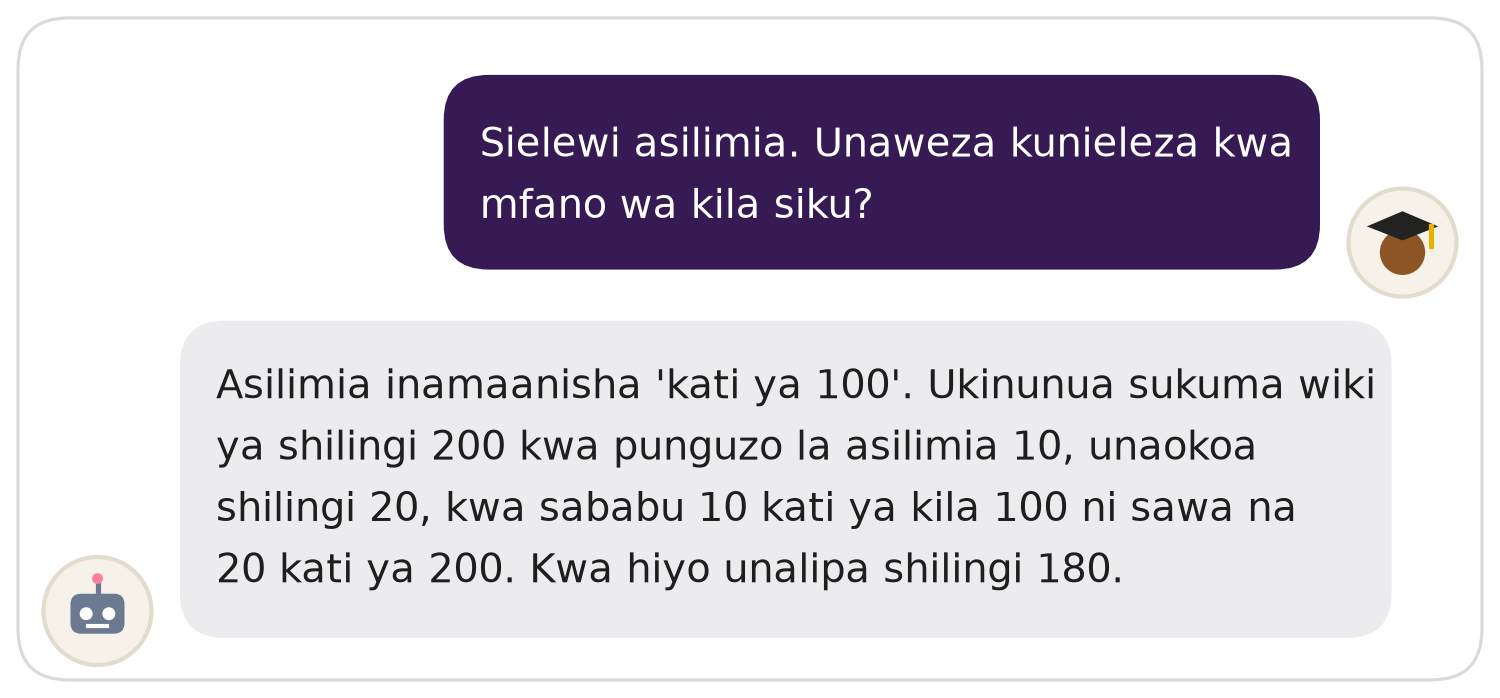

*Learner: "I don't understand percentages. Can you explain them with an everyday example?" Tutor: "Percent means 'out of 100'. If you buy sukuma wiki for 200 shillings with a 10 percent discount, you save 20 shillings, because 10 out of every 100 is the same as 20 out of 200. So you pay 180 shillings."*

Schools want to run the tutor **offline, on a laptop with a 4 GB GPU**. You can choose between two models from the Gemma 3 family:

* **Gemma 3 1B:** about 1 billion parameters
* **Gemma 3 4B:** about 4.3 billion parameters

> Gemma is a family of open AI models developed by Google DeepMind, available in different sizes.

We need to answer these questions:

1. Which model should we use: Gemma 3 1B or Gemma 3 4B?
2. How much GPU memory would it take to train the model?
3. How does the batch size change the memory needed for training?
4. How much memory does the model need to answer a learner's question?
5. How much memory can lower precision save, and at what cost?
6. Can the model run on a 4 GB laptop, so schools can use it offline?

> 💡 In this lab, you will get hands-on experience with code to answer them.

## 🚀 Before you start

### 1. Switch on a GPU

Go to **Runtime → Change runtime type**, choose **T4 GPU** and click **Save**. This ensures you are using a GPU.

### 2. Get access to the models

You need a way to access the models (**Gemma 3 1B** and **Gemma 3 4B**). There are two ways to do this in this practical. Pick **one**.

#### Option A: Use Hugging Face 🤗

[Hugging Face](https://huggingface.co) is a platform that hosts open-source models, datasets and demo apps shared by companies, researchers and the wider community. Gemma is gated, so you need an access token and you need to accept its terms of use.

1. Go to [Hugging Face](https://huggingface.co/) → **Settings → Access Tokens**.
2. Click **Create new token**, give it a name, and select **Read** access.
3. Copy the token and add it to **Colab → Secrets** with the name `HF_TOKEN`.
4. Open the [Gemma 3 1B](https://huggingface.co/google/gemma-3-1b-it) and [Gemma 3 4B](https://huggingface.co/google/gemma-3-4b-it) model pages and accept the terms of use to get access.

#### Option B: Use the copy on Google Drive 📁

Can't set up a Hugging Face account for the workshop? No worries. The models have been saved on Google Drive for you.

1. Open the link to the `AIRF_Gemma` folder that your facilitator shares.
2. Right-click the folder, choose **Organize → Add shortcut**, and pick **My Drive**.
3. When the setup cells ask, connect Colab to your Google Drive.

> 🤗 It is strongly recommended that you learn about Hugging Face even if you cannot use it during the workshop for this practical. It is where most open models, datasets and demos are shared, and you will use it again and again.

### 3. Run the setup cells

Run the four ⚙️ cells below, in order. The **Model loading utilities** cell chooses the source for you: Hugging Face if it finds your `HF_TOKEN` secret, and the Google Drive folder if not. If Colab asks for access to `HF_TOKEN` or to your Google Drive, allow it.

## ⚙️ Setup

> Run these cells once, in order. They install the libraries, check the GPU, connect to the models and define the helper functions. You don't need to read or change them.

In [ ]:
#@title ⚙️ Install packages: run this first
!pip install -q "transformers==5.19.0" "accelerate==1.15.0" "bitsandbytes==0.50.2"

In [ ]:
#@title ⚙️ Setup: run this next (you don't need to read it)
import os
import gc
import time
import shutil
import logging
import torch
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from huggingface_hub import (
    hf_hub_download,
    snapshot_download,
    whoami
)
from huggingface_hub.errors import GatedRepoError
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    Gemma3ForConditionalGeneration,
    BitsAndBytesConfig
)
from google.colab import (
    drive,
    userdata
)

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU found. Go to Runtime → Change runtime type → T4 GPU, then run this cell again."
    )

# When the rest of the model is fp32 (as on a T4), every int8 layer logs a warning for every new token
logging.getLogger("bitsandbytes").setLevel(logging.ERROR)

GB = 1e9
BYTES_PER_PARAM = {
    "fp32": 4,
    "bf16": 2,
    "int8": 1,
    "int4": 0.5
}
PARAMS = {
    "1B": 1.0e9,
    "4B": 4.3e9
}
# Chart colours: Google DeepMind blue with a warm orange, plus green and red for fits and does not fit
BLUE = "#1A73E8"
ORANGE = "#E8710A"
GREEN = "#1E8E3E"
RED = "#D93025"

GPU_TOTAL = torch.cuda.get_device_properties(0).total_memory

# T4s don't support bfloat16 natively, so "full precision" there is fp32
FULL = "bf16" if torch.cuda.get_device_capability()[0] >= 8 else "fp32"
DTYPE = torch.bfloat16 if FULL == "bf16" else torch.float32

print(f"GPU: {torch.cuda.get_device_name(0)}, {GPU_TOTAL / GB:.1f} GB")
print(f"Full precision on this GPU: {FULL}")

### 📦 Model loading utilities

Finds the Gemma models, checks that you can use them, and loads them for the rest of the lab.

In [ ]:
#@title ⚙️ Model loading utilities: run this next (you don't need to read it)
#@markdown **auto** uses Hugging Face if you added an `HF_TOKEN` secret, and the Google Drive folder if not. Pick **huggingface** or **drive** to choose yourself, then run this cell again.
MODEL_SOURCE = "auto" #@param ["auto", "huggingface", "drive"]

# Option A: the models on Hugging Face, and the files each one needs
HF_MODELS = {
    "1B": "google/gemma-3-1b-it",
    "4B": "google/gemma-3-4b-it"
}
HF_FILES = [
    "*.json",
    "*.safetensors",
    "*.model",
    "*.jinja"
]

# Option B: the Google Drive folder that holds the two model folders
MODEL_DIR = "/content/drive/MyDrive/AIRF_Gemma"
DRIVE_MODELS = {
    "1B": "gemma-3-1b-it",
    "4B": "gemma-3-4b-it"
}

_downloaded = {}


def _read_hf_token():
    """Returns your HF_TOKEN secret, or None if this notebook can't read one."""
    try:
        token = userdata.get("HF_TOKEN")
    except userdata.SecretNotFoundError:
        return None
    except userdata.NotebookAccessError:
        print("⚠️ Found an HF_TOKEN secret, but this notebook isn't allowed to read it. Open Secrets (the key icon on the left) and switch on Notebook access for HF_TOKEN.")
        return None
    return token.strip() or None


def _check_hugging_face(token):
    """Signs in with the token and checks it can download both models. Returns the username."""
    try:
        username = whoami(token=token)["name"]
    except Exception as error:
        raise RuntimeError(
            f"Hugging Face did not accept your HF_TOKEN ({error}). Create a new Read token and paste it into the HF_TOKEN secret."
        ) from error

    for repo in HF_MODELS.values():
        try:
            hf_hub_download(
                repo,
                "config.json",
                token=token
            )
        except GatedRepoError as error:
            raise RuntimeError(
                f"You are signed in to Hugging Face as {username}, but you haven't accepted the Gemma licence for {repo} yet. Accept it at https://huggingface.co/{repo}."
            ) from error
    return username


def _choose_source():
    """Picks Hugging Face or Google Drive, following MODEL_SOURCE. Returns the source and the token."""
    token = None if MODEL_SOURCE == "drive" else _read_hf_token()
    if MODEL_SOURCE == "huggingface" and token is None:
        raise RuntimeError(
            "MODEL_SOURCE is huggingface, but there is no HF_TOKEN secret. Follow Option A at the top of this notebook, or choose auto or drive."
        )

    if token is not None:
        try:
            username = _check_hugging_face(token)
            print(f"✅ Loading the models from Hugging Face (signed in as {username})")
            return "huggingface", token
        except RuntimeError as error:
            if MODEL_SOURCE == "huggingface":
                raise
            print(f"⚠️ {error}\nUsing the Google Drive folder for now. Fix this and run this cell again to switch to Hugging Face.")

    drive.mount("/content/drive")
    if os.path.exists(MODEL_DIR):
        print(f"✅ Loading the models from your Google Drive ({MODEL_DIR})")
    else:
        print(f"⚠️ Could not find {MODEL_DIR}. Sections 1, 2 and 4 still work, but from Section 3 you need the models. Follow Option A or Option B at the top of this notebook, then run this cell again.")
    return "drive", None


def _download_from_hugging_face(size):
    """Downloads a model from Hugging Face once. Later calls reuse the downloaded copy."""
    if size not in _downloaded:
        print(f"Getting Gemma 3 {size} from Hugging Face (the first download can take a few minutes)...")
        _downloaded[size] = snapshot_download(
            HF_MODELS[size],
            token=HF_TOKEN,
            allow_patterns=HF_FILES
        )
    return _downloaded[size]


def _copy_from_drive(size):
    """Copies a model from your Drive to this Colab machine once, so it loads quickly."""
    drive_path = f"{MODEL_DIR}/{DRIVE_MODELS[size]}"
    local_path = f"/content/{DRIVE_MODELS[size]}"
    if os.path.exists(local_path):
        return local_path

    if not os.path.exists(drive_path):
        raise FileNotFoundError(
            f"Could not find {drive_path}. Check that the AIRF_Gemma folder is in your Drive (Option B at the top of this notebook), or use Hugging Face instead (Option A)."
        )

    print(f"Copying Gemma 3 {size} from your Drive (first time only, this can take a few minutes)...")
    partial_path = local_path + ".partial"
    shutil.rmtree(
        partial_path,
        ignore_errors=True
    )
    shutil.copytree(
        drive_path,
        partial_path
    )
    os.rename(
        partial_path,
        local_path
    )
    return local_path


def model_path(size):
    """Makes sure Gemma 3 `size` is on this Colab machine, and returns its folder."""
    if LOADING_FROM == "huggingface":
        return _download_from_hugging_face(size)
    return _copy_from_drive(size)


def load_gemma(
    size="1B",
    quantization_config=None
):
    """Loads Gemma 3 `size` onto the GPU, quantized if you pass a BitsAndBytesConfig."""
    path = model_path(size)
    model_class = AutoModelForCausalLM if size == "1B" else Gemma3ForConditionalGeneration
    model = model_class.from_pretrained(
        path,
        dtype=DTYPE,
        quantization_config=quantization_config,
        device_map="cuda"
    ).eval()
    tokenizer = AutoTokenizer.from_pretrained(path)
    return model, tokenizer


LOADING_FROM, HF_TOKEN = _choose_source()

### 🧰 Helper functions

The explorers and charts, and the functions that measure memory and speed.

In [ ]:
#@title ⚙️ Helper functions: run this next (you don't need to read it)

def _safe_call(
    function,
    *args
):
    """Calls a learner's function, returning None if it is not finished yet."""
    try:
        return function(*args)
    except TypeError:
        return None


def format_gb(value):
    """Formats an estimate in GB, or reminds the learner to finish Section 3."""
    if value is None:
        return "(complete inference_memory_gb in Section 3 first)"
    return f"{value:.2f} GB"


def plot_comparison(
    labels,
    values,
    title,
    ylabel,
    unit,
    limit=None,
    limit_label=None
):
    """Simple bar chart with the value and its unit on each bar, and an optional limit line."""
    if any(value is None for value in values):
        print("Complete the configs in Section 5 first")
        return

    plt.figure(figsize=(7, 4))
    bars = plt.bar(
        [str(label) for label in labels],
        values,
        color=BLUE
    )
    plt.bar_label(
        bars,
        fmt=f"%g {unit}"
    )

    if limit is not None:
        plt.axhline(
            limit,
            color="black",
            linestyle="--",
            label=limit_label
        )
        plt.legend()

    plt.title(title)
    plt.ylabel(ylabel)
    plt.show()


def explore_batch_size(
    training_memory_fn,
    act_per_example_gb=1.5,
    gpu_gb=15
):
    """Slider: training memory of Gemma 3 1B (bf16) as batch size changes."""
    num_params = PARAMS["1B"]
    bytes_per_param = BYTES_PER_PARAM["bf16"]

    model_part = _safe_call(
        training_memory_fn,
        num_params,
        bytes_per_param,
        0
    )
    if model_part is None:
        print("Complete training_memory_gb in Section 1 first")
        return

    y_max = training_memory_fn(
        num_params,
        bytes_per_param,
        32 * act_per_example_gb
    ) * 1.35   # headroom so the legend never covers the bar

    def draw(batch_size):
        total = training_memory_fn(
            num_params,
            bytes_per_param,
            batch_size * act_per_example_gb
        )
        verdict = "fits" if total <= gpu_gb else "does NOT fit"

        plt.figure(figsize=(5, 5))
        plt.bar(
            ["Gemma 3 1B"],
            [model_part],
            color=BLUE,
            edgecolor="white",
            linewidth=2,
            label="Parameters + gradients + optimizer states"
        )
        plt.bar(
            ["Gemma 3 1B"],
            [total - model_part],
            bottom=[model_part],
            color=ORANGE,
            edgecolor="white",
            linewidth=2,
            label="Activations"
        )
        plt.axhline(
            gpu_gb,
            color="black",
            linestyle="--",
            label=f"T4 limit ({gpu_gb} GB)"
        )
        plt.ylim(
            0,
            y_max
        )
        plt.ylabel("Training memory (GB)")
        plt.title(f"Batch size {batch_size}: {total:.1f} GB, {verdict}")
        plt.legend(loc="upper left")
        plt.show()

    widgets.interact(
        draw,
        batch_size=widgets.IntSlider(
            value=1,
            min=1,
            max=32,
            step=1,
            description="Batch size",
            continuous_update=False
        )
    )


def explore_precision(
    inference_memory_fn,
    device_gb=4
):
    """Slider: estimated inference memory by model and precision."""
    check = _safe_call(
        inference_memory_fn,
        1,
        1
    )
    if check is None:
        print("Complete inference_memory_gb in Section 3 first")
        return

    def draw(
        model_size,
        precision
    ):
        estimate = inference_memory_fn(
            PARAMS[model_size],
            BYTES_PER_PARAM[precision]
        )
        fits = estimate < device_gb   # no room left at all counts as not fitting
        verdict = "fits" if fits else "does NOT fit"

        plt.figure(figsize=(5, 5))
        bars = plt.bar(
            [f"Gemma 3 {model_size}\n{precision}"],
            [estimate],
            color=GREEN if fits else RED
        )
        plt.bar_label(
            bars,
            fmt="%.2f GB"
        )
        plt.axhline(
            device_gb,
            color="black",
            linestyle="--",
            label=f"{device_gb} GB laptop GPU"
        )
        plt.ylim(
            0,
            22   # the largest estimate (4B in fp32) is 17.2 GB, plus room for the legend
        )
        plt.ylabel("Estimated memory, weights only (GB)")
        plt.title(f"Gemma 3 {model_size} in {precision}: {verdict}")
        plt.legend(loc="upper right")
        plt.show()

    widgets.interact(
        draw,
        model_size=widgets.ToggleButtons(
            options=list(PARAMS),
            description="Model"
        ),
        precision=widgets.SelectionSlider(
            options=list(BYTES_PER_PARAM),
            value="fp32",
            description="Precision",
            continuous_update=False
        )
    )


def _clear():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


def precision_name(quantization_config):
    """Names the precision of a config, or returns None if the config is still empty."""
    if quantization_config is None:
        return FULL
    if quantization_config.load_in_4bit:
        return "int4"
    if quantization_config.load_in_8bit:
        return "int8"
    return None


def _not_set_yet(size):
    """Placeholder result for a config that has not been completed yet."""
    print("Complete the configs in Section 5 first")
    return {
        "model": size,
        "precision": "not set",
        "after loading (GB)": None,
        "peak while generating (GB)": None,
        "seconds": None,
        "response": "(complete the configs in Section 5 first)"
    }


def generate_response(
    model,
    tokenizer,
    prompt,
    max_new_tokens=100
):
    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True
    ).to("cuda")

    start = time.time()
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False   # greedy: same input, same output
        )
    seconds = time.time() - start

    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    response = tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    ).strip()
    return response, seconds


def measure(
    size,
    prompt,
    quantization_config=None,
    max_new_tokens=100
):
    """Loads Gemma, generates one response, reports memory and speed."""
    name = precision_name(quantization_config)
    if name is None:
        return _not_set_yet(size)

    _clear()
    model, tokenizer = load_gemma(
        size,
        quantization_config
    )
    loaded = torch.cuda.memory_allocated() / GB

    response, secs = generate_response(
        model,
        tokenizer,
        prompt,
        max_new_tokens
    )
    peak = torch.cuda.max_memory_allocated() / GB

    del model
    _clear()

    return {
        "model": size,
        "precision": name,
        "after loading (GB)": round(
            loaded,
            2
        ),
        "peak while generating (GB)": round(
            peak,
            2
        ),
        "seconds": round(
            secs,
            1
        ),
        "response": response
    }


def _is_out_of_memory(error):
    if isinstance(
        error,
        torch.cuda.OutOfMemoryError
    ):
        return True
    return "out of memory" in str(error).lower()


def try_on_device(
    size,
    prompt,
    quantization_config=None,
    max_new_tokens=100,
    device_gb=4
):
    """Pretends this GPU only has `device_gb` of memory."""
    name = precision_name(quantization_config)
    if name is None:
        print("Complete the configs in Section 5 first")
        return

    # Fetch the model before limiting memory, so a first-time download is not mistaken for a failure
    model_path(size)

    _clear()
    fraction = min(
        1.0,
        device_gb * GB / GPU_TOTAL
    )
    torch.cuda.set_per_process_memory_fraction(fraction)
    model = None
    try:
        model, tokenizer = load_gemma(
            size,
            quantization_config
        )
        response, secs = generate_response(
            model,
            tokenizer,
            prompt,
            max_new_tokens
        )
        peak = torch.cuda.max_memory_allocated() / GB
        print(f"✅ Gemma 3 {size} in {name} fits on a {device_gb} GB GPU!")
        print(f"Peak memory: {peak:.2f} GB, time: {secs:.1f}s\n\n{response}")
    except Exception as error:
        if not _is_out_of_memory(error):
            raise
        print(f"❌ Gemma 3 {size} in {name} does not fit on a {device_gb} GB GPU. Try changing something.")
    finally:
        del model
        _clear()
        torch.cuda.set_per_process_memory_fraction(1.0)

## 1. Estimate training memory

From the lecture:

**Training Memory ≈ Parameter Memory + Gradient Memory + Optimizer State Memory + Activation Memory**

* Parameter memory = N × B (number of parameters × bytes per parameter)
* Gradients = 1× parameter memory
* Optimizer states (Adam) = 2× parameter memory

**Task:** complete the function. Work in GB (1 GB = 10⁹ bytes, stored in `GB`).

In [ ]:
def training_memory_gb(
    num_params,
    bytes_per_param,
    activation_gb
):
    parameter_memory_gb = None          # TODO
    gradient_memory_gb = None           # TODO
    optimizer_states_memory_gb = None   # TODO: assume Adam optimizer

    total_training_memory_gb = None     # TODO
    return total_training_memory_gb


# Lecture example: 8B model, bfloat16, 10 GB of activations. Should print 74.0
print(training_memory_gb(
    num_params=8e9,
    bytes_per_param=2,
    activation_gb=10
))

## 2. How batch size affects training memory

You want to fine-tune **Gemma 3 1B** in 16-bit (bfloat16) on this T4, with about **15 GB** usable.

**Assume** each example in a batch adds **1.5 GB** of activations.

Move the slider and watch the memory change.

In [ ]:
explore_batch_size(training_memory_gb)

### 🤔 Reflect

1. Which part of the memory grows with batch size?
2. You need a batch size of 32 for stable training, but it doesn't fit. What could you do to make it fit during training?

✍️ **Your answer:**

## 3. Estimate inference memory, then measure it

**Inference Memory ≈ Parameter Memory + Temporary Activation Memory**

Temporary activations are hard to predict, so we'll estimate the parameters only and see what reality says.

**Task:** complete the function, then estimate Gemma 3 1B.

In [ ]:
def inference_memory_gb(
    num_params,
    bytes_per_param,
    temp_activation_gb=0
):
    parameter_memory_gb = None          # TODO

    total_inference_memory_gb = None    # TODO
    return total_inference_memory_gb


estimate = inference_memory_gb(
    num_params=PARAMS["1B"],
    bytes_per_param=BYTES_PER_PARAM[FULL]
)
print(f"Estimated: {estimate} GB")

Now load Gemma 3 1B in full precision, generate a response, and measure. The first run downloads the model from Hugging Face or copies it from your Drive, so give it a minute or two.

In [ ]:
PROMPT = "A matatu ride costs 80 shillings. Wanjiku takes 6 rides. How much does she spend? Show your working."

original = measure(
    size="1B",
    prompt=PROMPT
)

print(f"Estimated:              {format_gb(estimate)}")
print(f"After loading:          {original['after loading (GB)']} GB")
print(f"Peak while generating:  {original['peak while generating (GB)']} GB")

### 🤔 Reflect

Why is the actual memory higher than your estimate?

✍️ **Your answer:**

## 4. How precision affects inference memory

**Task:** use your `inference_memory_gb` function to fill the table.

In [ ]:
table = pd.DataFrame({
    precision: {
        f"Gemma 3 {size}": None   # TODO: replace None using inference_memory_gb
        for size in PARAMS
    }
    for precision in BYTES_PER_PARAM
})
table

Now explore it visually. Use the buttons and slider: which combinations fit on a **4 GB** laptop GPU?

In [ ]:
explore_precision(inference_memory_gb)

### 🤔 Reflect

Halving the bytes halves the memory. What might we lose in return?

✍️ **Your answer:**

## 5. Quantize Gemma with bitsandbytes

**bitsandbytes** is a library that quantizes a model as it loads. You describe what you want in a `BitsAndBytesConfig`:

* **int8:** `load_in_8bit=True`
* **int4:** `load_in_4bit=True`, plus two settings:
  * `bnb_4bit_quant_type="nf4"`: a 4-bit format designed for neural network weights
  * `bnb_4bit_compute_dtype=DTYPE`: the precision used for the maths during generation

**Task:** create both configs.

In [ ]:
int8_config = BitsAndBytesConfig(
    # TODO
)

int4_config = BitsAndBytesConfig(
    # TODO
)

Now load Gemma 3 1B with each config and compare **memory** and **speed** with the original from Section 3.

In [ ]:
int8_result = measure(
    size="1B",
    prompt=PROMPT,
    quantization_config=int8_config
)

int4_result = measure(
    size="1B",
    prompt=PROMPT,
    quantization_config=int4_config
)

results = [original, int8_result, int4_result]
pd.DataFrame(results).drop(columns="response")

In [ ]:
precisions = [r["precision"] for r in results]

plot_comparison(
    labels=precisions,
    values=[r["peak while generating (GB)"] for r in results],
    title="Gemma 3 1B: peak memory, original vs quantized",
    ylabel="Peak memory (GB)",
    unit="GB"
)

plot_comparison(
    labels=precisions,
    values=[r["seconds"] for r in results],
    title="Gemma 3 1B: time to generate a response",
    ylabel="Time (s)",
    unit="s"
)

In [ ]:
for r in results:
    print(f"--- {r['precision']} ---")
    print(
        r["response"],
        "\n"
    )

### 🤔 Reflect

1. How much memory did quantization save? Is that exactly what Section 4 predicted?
2. Was the quantized model faster, and did the response change?

✍️ **Your answer:**

## 6. 🎯 Challenge: make Gemma fit on a 4 GB GPU

The school laptops have a **4 GB GPU**. Find a setup that runs on one **and** still gives a good response.

**Things you can change:**
* **Model:** `"1B"` or `"4B"`
* **Quantization:** `None` (full precision), `int8_config` or `int4_config`
* **Response length:** `max_new_tokens`
* **Prompt:** try your own question, in your own language

Use the explorer from Section 4 to predict before you try!

In [ ]:
# TODO: change these until it fits
try_on_device(
    size="4B",
    prompt=PROMPT,
    quantization_config=None,
    max_new_tokens=100,
    device_gb=4
)

### 🤔 Final reflection

1. What is the most capable setup you got running on 4 GB?
2. What did you give up to make it fit?

✍️ **Your answer:**

# Solutions

Please try to write the code yourself before looking at the solutions. You are free to use the Gemini in Colab integration or other coding assistants for assistance as well.

> 👀 Each solution is hidden. Click **Show code** on a cell (or double-click it) to see it. Running a solution cell replaces your own version of that code.

In [ ]:
#@title Section 1 solution: estimate training memory { display-mode: "form" }
def training_memory_gb(
    num_params,
    bytes_per_param,
    activation_gb
):
    parameter_memory_gb = num_params * bytes_per_param / GB
    gradient_memory_gb = parameter_memory_gb
    optimizer_states_memory_gb = 2 * parameter_memory_gb

    total_training_memory_gb = (
        parameter_memory_gb
        + gradient_memory_gb
        + optimizer_states_memory_gb
        + activation_gb
    )
    return total_training_memory_gb


# Lecture example: 8B model, bfloat16, 10 GB of activations. Should print 74.0
print(training_memory_gb(
    num_params=8e9,
    bytes_per_param=2,
    activation_gb=10
))

In [ ]:
#@title Section 3 solution: estimate inference memory { display-mode: "form" }
def inference_memory_gb(
    num_params,
    bytes_per_param,
    temp_activation_gb=0
):
    parameter_memory_gb = num_params * bytes_per_param / GB

    total_inference_memory_gb = parameter_memory_gb + temp_activation_gb
    return total_inference_memory_gb


estimate = inference_memory_gb(
    num_params=PARAMS["1B"],
    bytes_per_param=BYTES_PER_PARAM[FULL]
)
print(f"Estimated: {estimate} GB")

In [ ]:
#@title Section 4 solution: fill the precision table { display-mode: "form" }
table = pd.DataFrame({
    precision: {
        f"Gemma 3 {size}": round(
            inference_memory_gb(
                PARAMS[size],
                BYTES_PER_PARAM[precision]
            ),
            2
        )
        for size in PARAMS
    }
    for precision in BYTES_PER_PARAM
})
table

In [ ]:
#@title Section 5 solution: the bitsandbytes configs { display-mode: "form" }
int8_config = BitsAndBytesConfig(
    load_in_8bit=True
)

int4_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=DTYPE
)

In [ ]:
#@title Section 6 solution: one setup that fits on 4 GB { display-mode: "form" }
# One setup that fits: Gemma 3 1B in int8. int4 fits too, so compare the two responses.
try_on_device(
    size="1B",
    prompt=PROMPT,
    quantization_config=int8_config,
    max_new_tokens=100,
    device_gb=4
)